# HS4002 Week 9

## Principal components analysis

A principal component is a linear combination of the variables. PCA reduces them to a smaller number of uncorrelated components.

The worked example uses five GSS variables: income, occupational prestige, education, number of children, and age. Each is scaled to mean 0 and SD 1. We fit the model with `sklearn.decomposition.PCA` and draw the scree plot with `plotnine`.


In [1]:
# !pip install pandas numpy plotnine scikit-learn statsmodels

import pandas as pd
import numpy as np
from plotnine import *
import warnings
warnings.filterwarnings('ignore')


In [2]:
raw_df = pd.read_csv("gss2022_mini2.csv")

chosen_variables = [
	'id', 'age', 'happy', 'yrlvmus', 'yrartxbt', 'yrmovie', 'yrcreat',
	'income16', 'prestg10', 'degree', 'biokids', 'educ'
]
df = raw_df[chosen_variables].copy()

income_map = {
	1: 500,    2: 2000,   3: 3500,   4: 4500,   5: 5500,   6: 6500,
	7: 7500,   8: 9000,   9: 11250,  10: 13750, 11: 16250, 12: 18750,
	13: 21250, 14: 23750, 15: 27500, 16: 32500, 17: 37500, 18: 45000,
	19: 55000, 20: 67500, 21: 82500, 22: 100000, 23: 120000, 24: 140000,
	25: 160000, 26: 250000
}
df['income_cont'] = df['income16'].map(income_map)

df['binary_lvmus']  = (df['yrlvmus']  == 1).astype(int)
df['binary_artxbt'] = (df['yrartxbt'] == 1).astype(int)
df['binary_movie']  = (df['yrmovie']  == 1).astype(int)
df['binary_creat']  = (df['yrcreat']  == 1).astype(int)
df['ba_binary']     = (df['degree'] >= 3).astype(int)
df['happy_bin']     = (df['happy'] <= 2).astype(int)


# Steps

1. Choose the variables.
2. Scale each one to mean 0 and SD 1.
3. Fit the PCA.
4. Decide how many components to keep. The scree plot is the guide. There is no single rule.
5. Read the loadings.
6. Use the components in a plot or a regression.


## 1. Choose the variables

`income_cont` is income in dollars. `prestg10` is occupational prestige. `educ` is years of schooling. `biokids` is the number of children. `age` is age in years.


In [3]:
cols = ["income_cont", "prestg10", "educ", "biokids", "age"]
work = df.dropna(subset=cols).copy()
work[cols].describe().round(1)


,income_cont,prestg10,educ,biokids,age
count,1056.0,1056.0,1056.0,1056.0,1056.0
mean,86222.1,46.8,14.9,1.6,50.9
std,72378.7,13.3,2.7,1.5,17.3
min,500.0,17.0,2.0,0.0,18.0
25%,32500.0,36.0,13.0,0.0,36.0
50%,67500.0,47.0,15.0,2.0,51.0
75%,120000.0,59.0,16.0,2.0,66.0
max,250000.0,80.0,20.0,11.0,89.0


## 2--3. Scale, then fit

`StandardScaler` subtracts the mean and divides by the standard deviation. Without that step, income, which is measured in dollars, would dominate the first component.


In [4]:
from sklearn.preprocessing import StandardScaler
from sklearn.decomposition import PCA

X = StandardScaler().fit_transform(work[cols])
pca = PCA().fit(X)

prop = pca.explained_variance_ratio_
print(pd.DataFrame({
    "Standard deviation": pca.explained_variance_ ** 0.5,
    "Proportion of variance": prop,
    "Cumulative proportion": prop.cumsum(),
}, index=["PC1", "PC2", "PC3", "PC4", "PC5"]).T.round(3))


                          PC1    PC2    PC3    PC4    PC5
Standard deviation      1.368  1.127  0.882  0.781  0.689
Proportion of variance  0.374  0.254  0.155  0.122  0.095
Cumulative proportion   0.374  0.628  0.783  0.905  1.000


PC1 accounts for 37.4 per cent of the variance. The first two components together account for 62.8 per cent.


## 4. Loadings

In `sklearn`, each row of `pca.components_` is one component. Transposing it puts the variables in the rows, so each column is a component. A large loading means that variable defines that component.


In [5]:
loadings = pd.DataFrame(
    pca.components_.T,
    index=cols,
    columns=["PC1", "PC2", "PC3", "PC4", "PC5"],
)
print(loadings.round(3))


               PC1    PC2    PC3    PC4    PC5
income_cont  0.524  0.009 -0.517  0.676 -0.030
prestg10     0.592  0.095  0.042 -0.457 -0.656
educ         0.594 -0.112  0.209 -0.268  0.721
biokids     -0.098  0.710 -0.560 -0.351  0.223
age          0.109  0.689  0.612  0.373 -0.022


How would you describe PC1 and PC2?

PC1 loads on income, occupational prestige, and education. PC2 loads on number of children and age.


## 5. How many components?

Look for an elbow in the scree plot: the point where adding another component buys little extra variance.


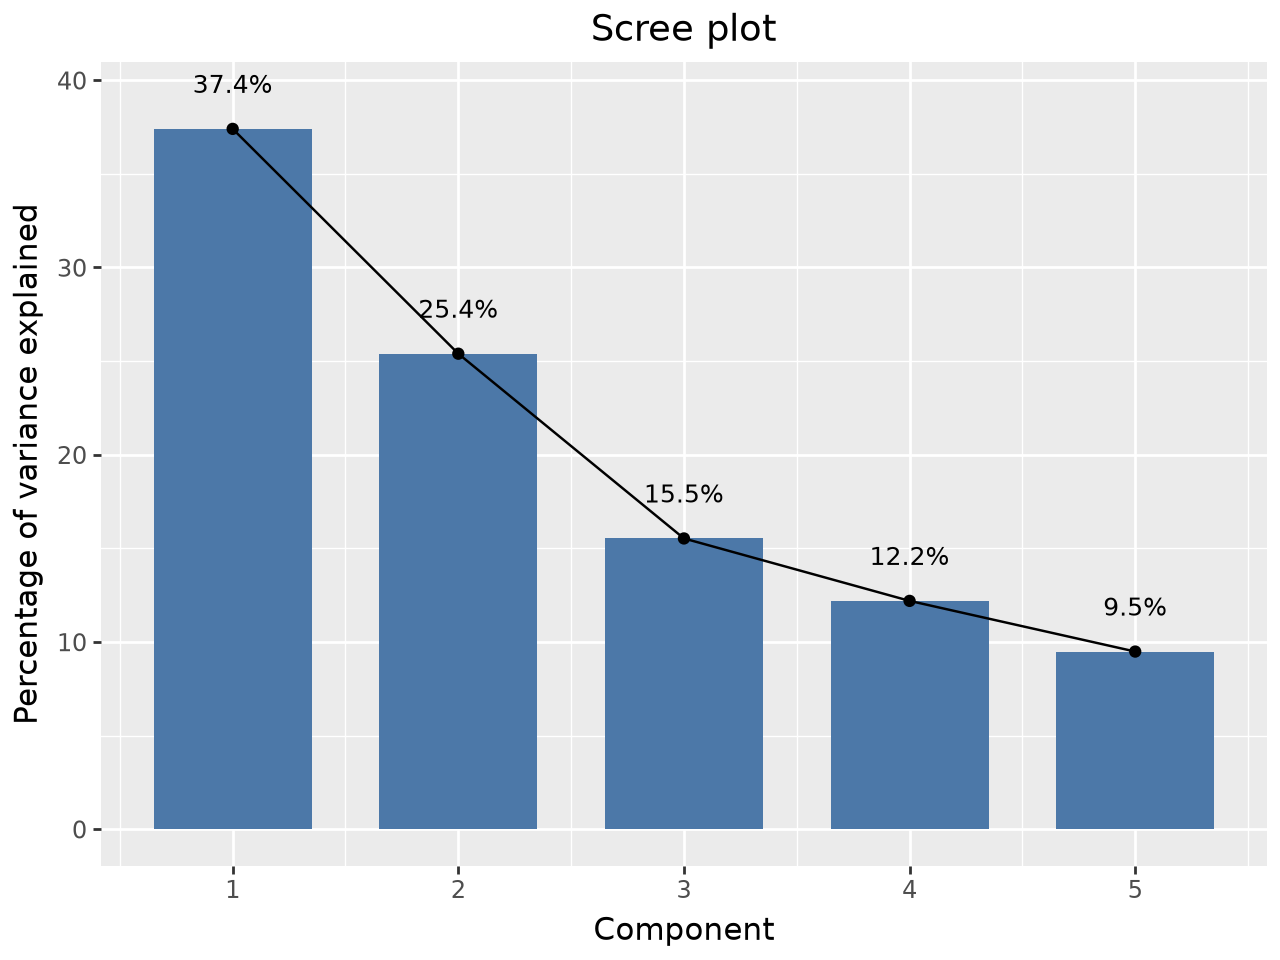

In [6]:
scree = pd.DataFrame({
    "component": range(1, 6),
    "percent": pca.explained_variance_ratio_ * 100,
})
scree["label"] = scree["percent"].map(lambda p: f"{p:.1f}%")

(
    ggplot(scree, aes("component", "percent"))
    + geom_col(fill="#4C78A8", width=0.7)
    + geom_line(aes(group=1))
    + geom_point()
    + geom_text(aes(label="label"), nudge_y=1.6, size=9, va="bottom")
    + labs(x="Component", y="Percentage of variance explained", title="Scree plot")
)


## 6. Use the components

The first two components locate each person in a plane. Colour the points by whether the person has a BA. A BA was not one of the five variables in the PCA, so the colour is a separate fact about the person.


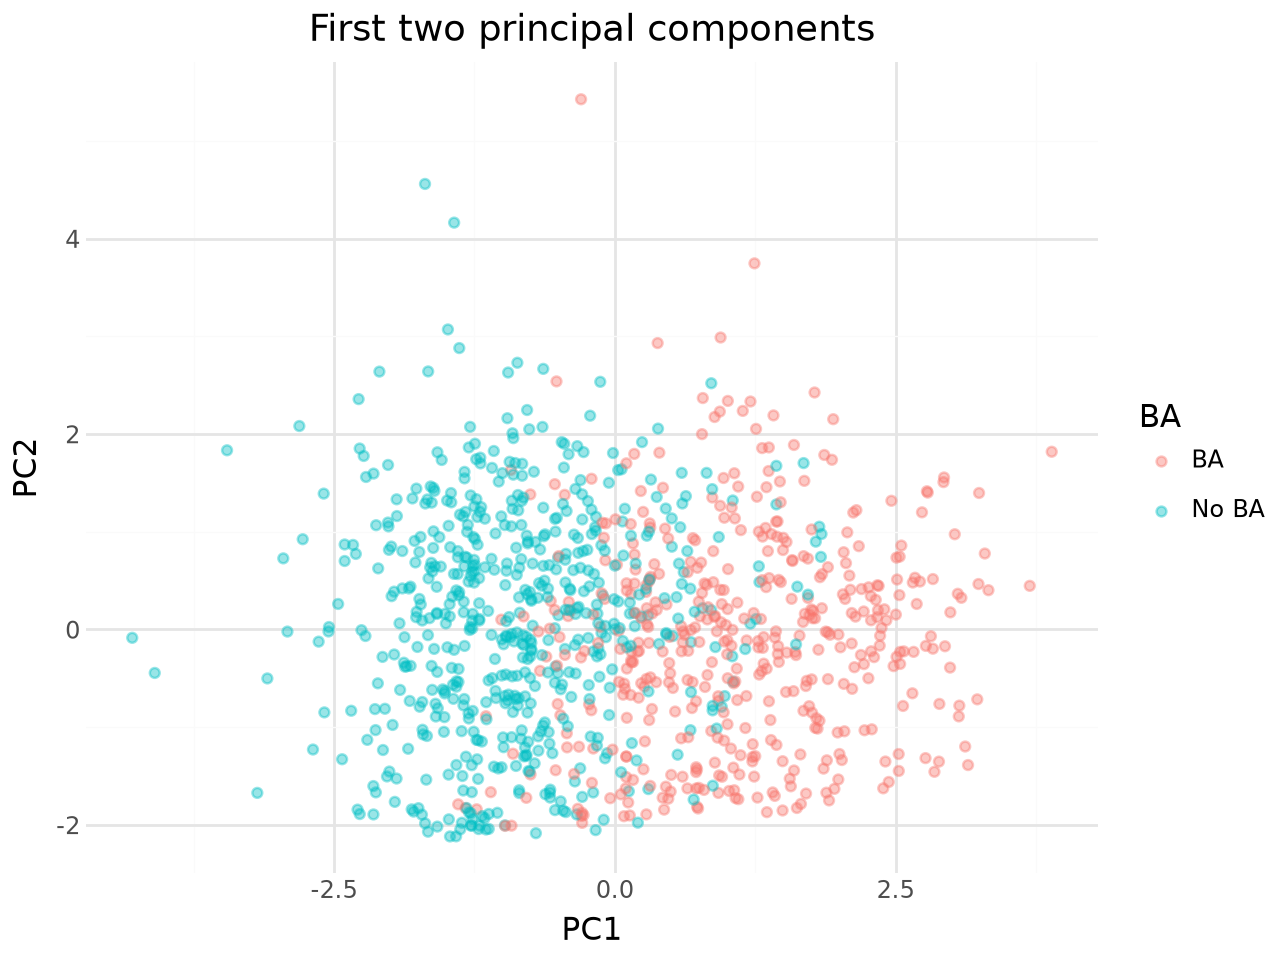

In [7]:
scores = pca.transform(X)
plot_df = work.copy()
plot_df["PC1"] = scores[:, 0]
plot_df["PC2"] = scores[:, 1]
plot_df["BA"] = np.where(plot_df["ba_binary"] == 1, "BA", "No BA")

(
    ggplot(plot_df, aes("PC1", "PC2", color="BA"))
    + geom_point(alpha=0.4, size=1.5)
    + theme_minimal()
    + labs(x="PC1", y="PC2", title="First two principal components")
)


## 7. A linear model for PC1

PC1 is the dependent variable. `ba_binary` is the independent variable: 1 is a BA, 0 is not.

This is an OLS model. The coefficient on `ba_binary` is the expected difference in PC1 between a person with a BA and a person without one.


In [8]:
import statsmodels.formula.api as smf

# Fit OLS model with PC1 as dependent variable and ba_binary as independent variable
ols_pc1 = smf.ols("PC1 ~ ba_binary", data=plot_df).fit()
print(ols_pc1.summary())


                            OLS Regression Results                            
Dep. Variable:                    PC1   R-squared:                       0.508
Model:                            OLS   Adj. R-squared:                  0.508
Method:                 Least Squares   F-statistic:                     1090.
Date:                Mon, 19 Oct 2026   Prob (F-statistic):          9.80e-165
Time:                        23:34:04   Log-Likelihood:                -1453.9
No. Observations:                1056   AIC:                             2912.
Df Residuals:                    1054   BIC:                             2922.
Df Model:                           1                                         
Covariance Type:            nonrobust                                         
                 coef    std err          t      P>|t|      [0.025      0.975]
------------------------------------------------------------------------------
Intercept     -0.8650      0.039    -21.911      0.0

The OLS regression shows that holding a bachelor's degree is associated with an expected increase of 1.964 units in PC1 (p < 0.001) relative to not having a degree. Because PC1 reflects socioeconomic status, having a college degree is strongly and positively related to higher standing, with educational attainment alone explaining 50.8 percent of the variance in PC1.

## 8. A logit model for a BA

`ba_binary` is now the dependent variable, and PC1 and PC2 are the independent variables. `ba_binary` is coded 0 or 1, so we fit a logit.

The coefficient is the expected change in the log odds of having a BA. Exponentiating it gives the factor by which the odds change.


In [9]:
# Fit logit model with ba_binary as dependent variable and PC1, PC2 as independent variables
logit_ba = smf.logit("ba_binary ~ PC1 + PC2", data=plot_df).fit()
print(logit_ba.summary())

# Exponentiate coefficients to get odds ratios
odds_ratios_ba = pd.DataFrame({
    "Coefficient": logit_ba.params,
    "Odds Ratio (exp)": np.exp(logit_ba.params),
    "p-value": logit_ba.pvalues
})
print("\nOdds Ratios:")
print(odds_ratios_ba.round(4))


Optimization terminated successfully.
         Current function value: 0.340435
         Iterations 7
                           Logit Regression Results                           
Dep. Variable:              ba_binary   No. Observations:                 1056
Model:                          Logit   Df Residuals:                     1053
Method:                           MLE   Df Model:                            2
Date:                Mon, 19 Oct 2026   Pseudo R-squ.:                  0.5037
Time:                        23:34:04   Log-Likelihood:                -359.50
converged:                       True   LL-Null:                       -724.43
Covariance Type:            nonrobust   LLR p-value:                3.259e-159
                 coef    std err          z      P>|z|      [0.025      0.975]
------------------------------------------------------------------------------
Intercept     -0.3769      0.095     -3.972      0.000      -0.563      -0.191
PC1            2.0936      0.

In the logit model, PC1 has a positive and statistically significant coefficient of 2.094 (p < 0.001, odds ratio = 8.11), indicating that each one-unit increase in the socioeconomic component multiplies the odds of holding a bachelor's degree by about 8.11, holding PC2 constant. In contrast, PC2 has a negative coefficient of -0.392 (p < 0.001, odds ratio = 0.68), meaning that higher values on the age and family component reduce the odds of having a degree by about 32 percent, controlling for PC1.

# Independent exercise

Use `happy_bin` as the dependent variable. Build the components from `income_cont`, `prestg10`, `educ`, `age`, and the four cultural-participation indicators (`binary_lvmus`, `binary_artxbt`, `binary_movie`, `binary_creat`). Leave `happy_bin` out of the PCA.

1. Scale each variable to mean 0 and SD 1, then fit a PCA.
2. Print the proportion of variance and the cumulative proportion.
3. Draw a scree plot with `plotnine` and decide how many components to keep.
4. Print the loadings and describe the first two components.
5. Scatter PC1 against PC2, coloured by happiness.
6. Fit a logit of `happy_bin` on the components you kept, and interpret the coefficients.


## 1. Scale each variable to mean 0 and SD 1, then fit a PCA

In [10]:
# Define variables for PCA
ex_cols = [
    'income_cont', 'prestg10', 'educ', 'age',
    'binary_lvmus', 'binary_artxbt', 'binary_movie', 'binary_creat'
]

# Ensure complete cases for the 8 variables and happy
ex_work = df.dropna(subset=ex_cols + ['happy']).copy()

# Scale variables to mean 0 and SD 1
scaler = StandardScaler()
X_ex = scaler.fit_transform(ex_work[ex_cols])

# Fit PCA
pca_ex = PCA().fit(X_ex)
print(f"Number of observations: {len(ex_work)}")


Number of observations: 2829


## 2. Proportion of variance and cumulative proportion

In [11]:
prop_ex = pca_ex.explained_variance_ratio_
var_table = pd.DataFrame({
    "Standard deviation": pca_ex.explained_variance_ ** 0.5,
    "Proportion of variance": prop_ex,
    "Cumulative proportion": prop_ex.cumsum(),
}, index=[f"PC{i+1}" for i in range(len(ex_cols))]).T.round(3)

print(var_table)


                          PC1    PC2    PC3    PC4    PC5    PC6    PC7    PC8
Standard deviation      1.607  1.300  1.005  0.848  0.793  0.722  0.710  0.590
Proportion of variance  0.323  0.211  0.126  0.090  0.079  0.065  0.063  0.043
Cumulative proportion   0.323  0.534  0.660  0.750  0.829  0.894  0.957  1.000


## 3. Scree plot and decision on number of components to keep

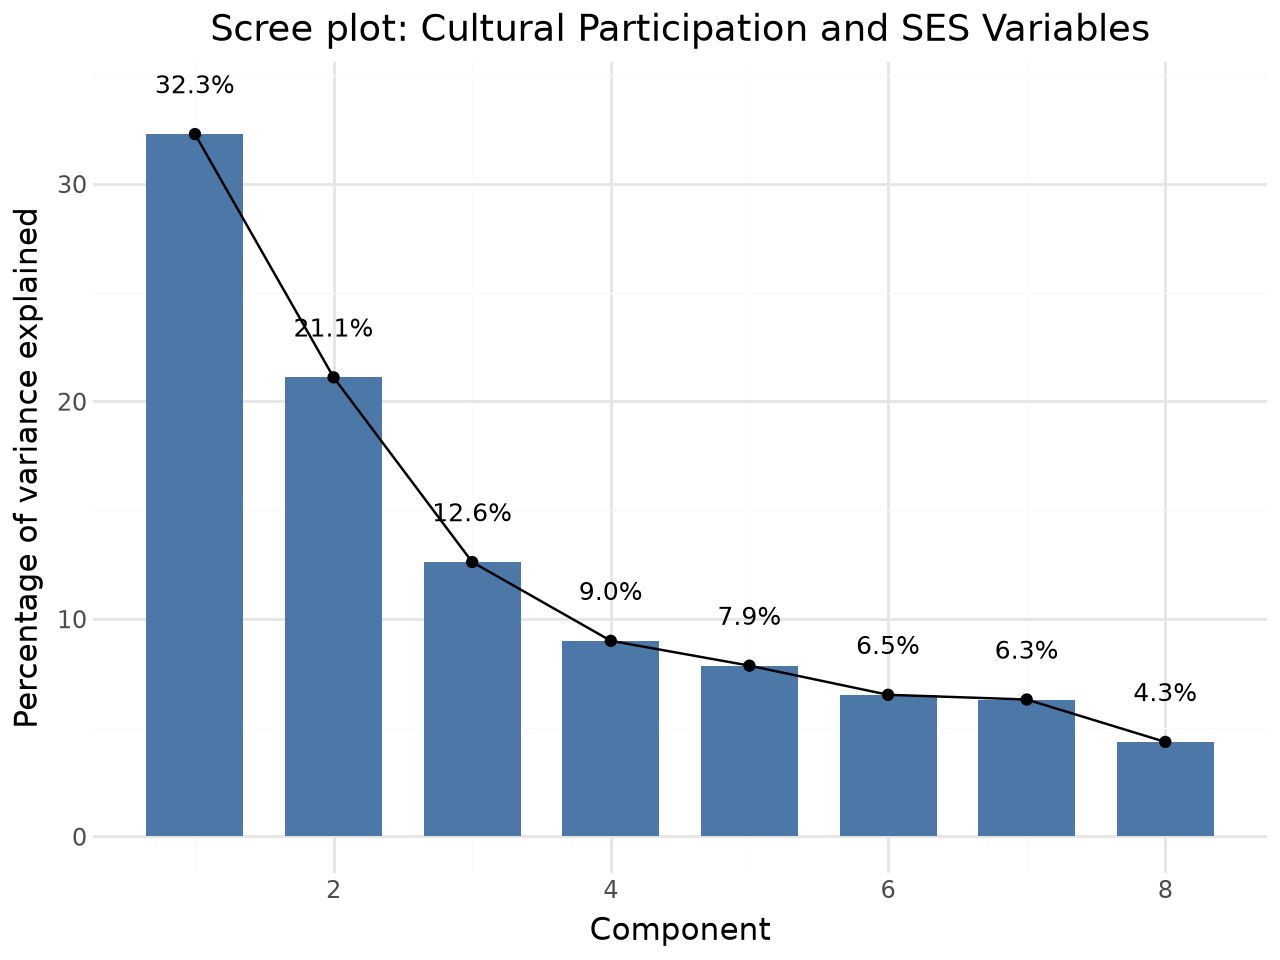

In [12]:
scree_ex = pd.DataFrame({
    "component": range(1, len(ex_cols) + 1),
    "percent": pca_ex.explained_variance_ratio_ * 100,
})
scree_ex["label"] = scree_ex["percent"].map(lambda p: f"{p:.1f}%")

(
    ggplot(scree_ex, aes("component", "percent"))
    + geom_col(fill="#4C78A8", width=0.7)
    + geom_line(aes(group=1))
    + geom_point()
    + geom_text(aes(label="label"), nudge_y=1.6, size=9, va="bottom")
    + labs(
        x="Component",
        y="Percentage of variance explained",
        title="Scree plot: Cultural Participation and SES Variables"
    )
    + theme_minimal()
)


Both the scree plot elbow and Kaiser's criterion support retaining two principal components. The scree plot shows a clear bend after the second component, with explained variance dropping from 32.3 percent for PC1 and 21.1 percent for PC2 to 12.6 percent for PC3. Together, the first two components account for 53.4 percent of the total variance and have eigenvalues greater than one, providing a parsimonious summary that cleanly separates cultural activities from socioeconomic status.

## 4. Loadings and description of the first two components

In [13]:
loadings_ex = pd.DataFrame(
    pca_ex.components_.T,
    index=ex_cols,
    columns=[f"PC{i+1}" for i in range(len(ex_cols))],
)
print("Loadings matrix (round to 3 decimal places):")
print(loadings_ex.round(3))


Loadings matrix (round to 3 decimal places):
                 PC1    PC2    PC3    PC4    PC5    PC6    PC7    PC8
income_cont    0.190  0.515 -0.182 -0.340  0.723 -0.148 -0.060 -0.026
prestg10       0.233  0.545  0.060  0.185 -0.389 -0.422  0.529  0.028
educ           0.277  0.513 -0.032  0.222 -0.277  0.522 -0.511 -0.017
age           -0.007  0.096  0.976 -0.124  0.110 -0.006 -0.085 -0.065
binary_lvmus   0.505 -0.196  0.051 -0.267 -0.062  0.062  0.028  0.790
binary_artxbt  0.468 -0.192  0.041  0.141  0.228  0.516  0.535 -0.344
binary_movie   0.448 -0.191 -0.062 -0.516 -0.333 -0.266 -0.243 -0.501
binary_creat   0.397 -0.231  0.047  0.654  0.264 -0.432 -0.319 -0.027


PC1 represents cultural participation, loading strongly and positively on all four cultural activities: attending live music (0.505), visiting art exhibits (0.468), going to movies (0.448), and doing creative work (0.397), with moderate positive loadings on education and income. PC2 reflects socioeconomic status, loading heavily on occupational prestige (0.545), income (0.515), and education (0.513) while loading slightly negatively on the cultural participation indicators.

## 5. Scatter PC1 against PC2, coloured by happiness

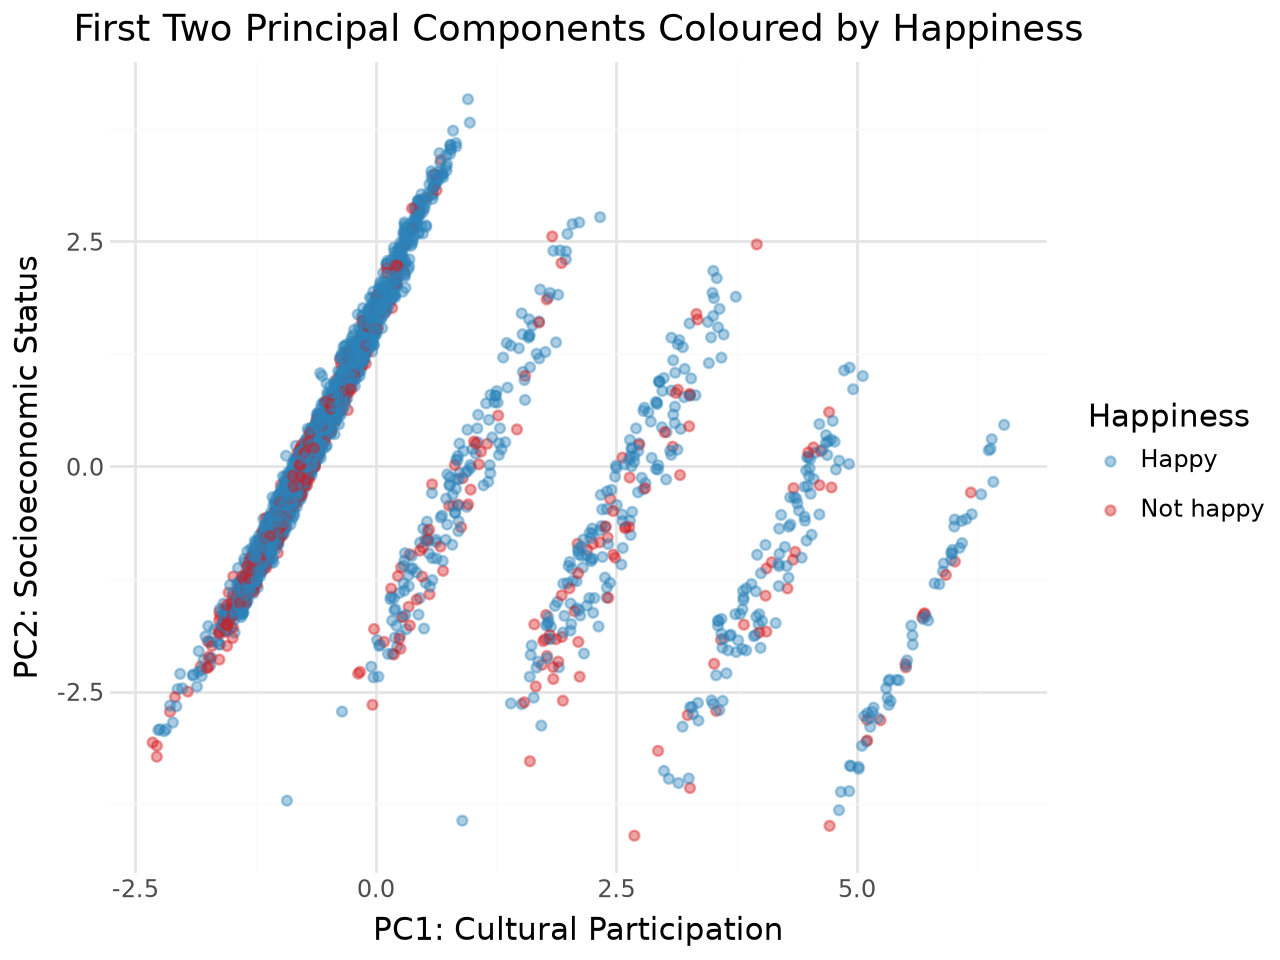

In [14]:
scores_ex = pca_ex.transform(X_ex)
plot_ex = ex_work.copy()
plot_ex["PC1"] = scores_ex[:, 0]
plot_ex["PC2"] = scores_ex[:, 1]
plot_ex["Happiness"] = np.where(plot_ex["happy_bin"] == 1, "Happy", "Not happy")

(
    ggplot(plot_ex, aes("PC1", "PC2", color="Happiness"))
    + geom_point(alpha=0.4, size=1.5)
    + scale_color_manual(values={"Happy": "#2B83BA", "Not happy": "#D7191C"})
    + theme_minimal()
    + labs(
        x="PC1: Cultural Participation",
        y="PC2: Socioeconomic Status",
        title="First Two Principal Components Coloured by Happiness",
        color="Happiness"
    )
)


## 6. Fit a logit of `happy_bin` on the components and interpret

In [15]:
# Fit logit model with happy_bin as dependent variable on the kept components (PC1, PC2)
logit_happy = smf.logit("happy_bin ~ PC1 + PC2", data=plot_ex).fit()
print(logit_happy.summary())

# Display odds ratios and 95% confidence intervals
or_table = pd.DataFrame({
    "Coefficient": logit_happy.params,
    "Std. Error": logit_happy.bse,
    "z": logit_happy.tvalues,
    "p-value": logit_happy.pvalues,
    "Odds Ratio": np.exp(logit_happy.params),
    "OR 2.5%": np.exp(logit_happy.conf_int()[0]),
    "OR 97.5%": np.exp(logit_happy.conf_int()[1]),
})
print("\nOdds Ratios and 95% Confidence Intervals:")
print(or_table.round(4))


Optimization terminated successfully.
         Current function value: 0.518643
         Iterations 6
                           Logit Regression Results                           
Dep. Variable:              happy_bin   No. Observations:                 2829
Model:                          Logit   Df Residuals:                     2826
Method:                           MLE   Df Model:                            2
Date:                Mon, 19 Oct 2026   Pseudo R-squ.:                 0.02999
Time:                        23:34:05   Log-Likelihood:                -1467.2
converged:                       True   LL-Null:                       -1512.6
Covariance Type:            nonrobust   LLR p-value:                 1.989e-20
                 coef    std err          z      P>|z|      [0.025      0.975]
------------------------------------------------------------------------------
Intercept      1.2845      0.047     27.256      0.000       1.192       1.377
PC1            0.1034      0.

The logit model indicates that both cultural participation and socioeconomic status are positive, statistically significant predictors of happiness (p < 0.001). Holding socioeconomic status constant, each one-unit increase in PC1 increases the odds of being happy by about 11.3 percent (odds ratio = 1.11, 95% CI [1.05, 1.18]). Holding cultural participation constant, each one-unit increase in PC2 increases the odds of being happy by about 37.8 percent (odds ratio = 1.38, 95% CI [1.28, 1.49]), showing that while cultural engagement contributes positively to well-being, socioeconomic status exerts a substantially stronger effect.